# Predicting long-term rents in Portugal one year ahead
## Notebook 2 - Data preparation and machine learning (regression)

**Problem type:** regression - I predict a number, the **median rent in €/m² of new long-term leases**
in each municipality, **one year (4 quarters) later**.

| Step | Section |
|---|---|
| Cleaning | 1 |
| Feature engineering (X) and target (y) | 2 |
| Exploration and feature selection | 3 |
| Train/test split and a simple baseline | 4 |
| Preparing the features (imputer, normaliser, one-hot encoding) | 5 |
| Comparing regression models with cross-validation | 6 |
| Hyperparameter tuning (GridSearchCV, RandomizedSearchCV) | 7 |
| Results on the test year (MAE, RMSE, R², confusion matrix) | 8 |
| Feature importance | 9 |
| 2027 outlook (forecast) | 10 |
| Export for Tableau | 11 |
| Conclusions | 12 |

In [1]:
import sys
sys.path.append("..")

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from src.config import (INE_INDICATORS, MODEL_DATASET_FILE, PANEL_FILE, TABLEAU_DIR,
                        TEST_START_QUARTER)
from src.data_acquisition import fetch_ine_indicator, ine_json_to_dataframe
from src.data_cleaning import (build_panel, clean_population, clean_quarterly_indicator,
                               quick_check, region_names)
from src.feature_engineering import add_local_growth_target, build_model_dataset, drop_unusable_rows
from src.evaluation import regression_scores, time_split, top_20_hit_rate
from src.modelling import (CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET, FeaturePreparer,
                           candidate_models, predict_rent)
from src.plots import AREA_COLORS, DARK_GREY, GREY, HIGHLIGHT, TEXT, apply_style, horizontal_bars, save

apply_style()
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Cleaning

| Problem in the raw data | Technique |
|---|---|
| Country, regions, municipalities and parishes mixed together | filter rows: 7-character `geocod` starting with `1` (the Azores and Madeira are out of scope) |
| Numbers stored as text, suppressed values shown as `'-'` | `pd.to_numeric(errors="coerce")` -> NaN |
| Periods written as `"3rd Quarter 2024"` | parse into a pandas `Period("2024Q3")` |
| Population split by sex and age (long format) | filter both sexes, `pivot_table` to wide, compute age shares |
| Different place names across sources | join on the 4-digit **municipality code**, never on names |

In [2]:
rent_raw = ine_json_to_dataframe(fetch_ine_indicator(INE_INDICATORS["rent"]))
rent = clean_quarterly_indicator(rent_raw, "rent_m2")
leases = clean_quarterly_indicator(ine_json_to_dataframe(fetch_ine_indicator(INE_INDICATORS["leases"])), "new_leases")
population = clean_population(ine_json_to_dataframe(fetch_ine_indicator(INE_INDICATORS["population"])))
region_name = region_names(rent_raw)

for table, name in [(rent, "rent"), (leases, "leases"), (population, "population")]:
    quick_check(table, name)

--- rent ---
rows, columns: (7228, 5) | duplicated rows: 0
missing values: {'rent_m2': 1482}
--- leases ---
rows, columns: (7228, 5) | duplicated rows: 0
missing values: {'new_leases': 1576}
--- population ---
rows, columns: (1390, 5) | duplicated rows: 0
missing values: none


In [3]:
rent.head()

,municipality_code,municipality,region_code,quarter,rent_m2
7,1315,Valongo,11A,2020Q1,5.24
8,1316,Vila do Conde,11A,2020Q1,4.75
9,1317,Vila Nova de Gaia,11A,2020Q1,6.40
10,1318,Trofa,11A,2020Q1,3.97
11,1304,Gondomar,11A,2020Q1,5.22


### 1.1 The panel: one row per municipality and quarter

`build_panel` creates **every** municipality x quarter combination first, then fills in the values.
That way `shift(4)` always means *exactly 4 quarters*, even when some quarters are missing.

In [4]:
panel = build_panel(rent, leases)
quick_check(panel, "panel")
print(panel["municipality_code"].nunique(), "municipalities x", panel["quarter"].nunique(), "quarters")

--- panel ---
rows, columns: (7228, 6) | duplicated rows: 0
missing values: {'rent_m2': 1482, 'new_leases': 1576}
278 municipalities x 26 quarters


### 1.2 Where is the rent missing?

INE does not publish a median when there are too few contracts. I check that this is the reason:

municipalities never missing: 198
municipalities always missing: 33
smallest number of leases in a row WITH a rent: 33.0


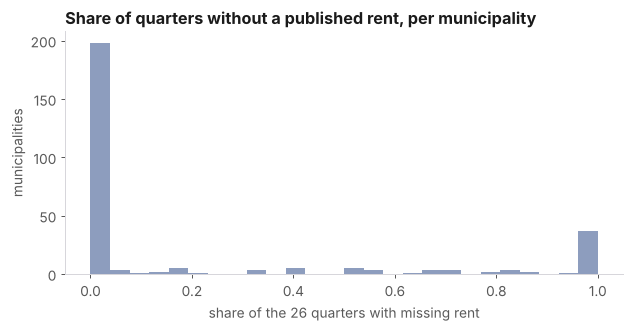

In [5]:
panel["rent_missing"] = panel["rent_m2"].isna()
missing_by_municipality = panel.groupby("municipality")["rent_missing"].mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(missing_by_municipality, bins=26, color=HIGHLIGHT)
ax.set(title="Share of quarters without a published rent, per municipality",
       xlabel="share of the 26 quarters with missing rent", ylabel="municipalities")
save(fig, "01_missing_rent_by_municipality.png")

print("municipalities never missing:", (missing_by_municipality == 0).sum())
print("municipalities always missing:", (missing_by_municipality == 1).sum())
print("smallest number of leases in a row WITH a rent:", panel.loc[~panel["rent_missing"], "new_leases"].min())

**Decision:** I do **not** impute the rent. A made-up rent would also become a made-up *target* (y).
Rows without a rent are dropped, so the model only covers municipalities with an active rental market
(at least ~33 new contracts a year).

In [6]:
panel = panel.drop(columns="rent_missing")
panel.to_csv(PANEL_FILE, index=False)

## 2. Feature engineering: X and y

**Golden rule:** a feature may only use information I already have *in that quarter*.
If it used the future, the model would "cheat" (**data leakage**).

**Candidate features (X)** - 8 numbers + 1 category (section 3.4 selects the final ones):

| Feature | Meaning |
|---|---|
| `rent_m2` | rent today, €/m² |
| `rent_growth_1y` | rent growth over the last 12 months |
| `rent_vs_region` | rent today / median rent of the NUTS III region (cheap or expensive vs neighbours) |
| `growth_vs_region` | last year's growth minus the region's growth |
| `log_new_leases` | size of the rental market (log of new contracts) |
| `leases_per_1000` | new contracts per 1,000 residents |
| `log_population` | size of the municipality (log, previous year) |
| `share_age_65_plus` | share of residents aged 65+ (previous year) |
| `area` (category) | Lisbon metro / Porto metro / Rest of Portugal |

**Target (y)**

- What I finally want: `target_rent_next_year` = the rent 4 quarters later.
- Rents grow a lot every year, and the growth is similar everywhere. So I split the prediction in **two simple steps**:
  1. **Baseline:** every rent grows by the *average* growth seen in the training years.
  2. **Machine learning:** the model predicts how much **faster or slower** than that average each municipality grows.
     This is the column `target_local_growth` (y).

```
predicted rent = rent today x (1 + average growth + model prediction)
```

In [7]:
features_all_rows = build_model_dataset(panel, population)
model_dataset = add_local_growth_target(drop_unusable_rows(features_all_rows))
model_dataset["region_name"] = model_dataset["region_code"].map(region_name)
model_dataset[["municipality", "quarter"] + NUMERIC_FEATURES + ["log_population"] + CATEGORICAL_FEATURES +
              ["target_rent_next_year", TARGET]].head()

kept 3,788 of 7,228 rows (230 municipalities)


,municipality,quarter,rent_m2,rent_growth_1y,rent_vs_region,growth_vs_region,log_new_leases,leases_per_1000,share_age_65_plus,log_population,area,target_rent_next_year,target_local_growth
0,Águeda,2021Q1,3.73,0.013587,0.994667,0.000000,5.998937,8.504877,0.25449,10.763568,Rest of Portugal,3.93,-0.004768
1,Águeda,2021Q2,3.87,0.045946,0.989770,-0.009054,6.086775,9.287664,0.25449,10.763568,Rest of Portugal,4.05,-0.029347
2,Águeda,2021Q3,3.87,0.051630,0.989770,0.026967,6.077642,9.203038,0.25449,10.763568,Rest of Portugal,4.17,-0.006581
3,Águeda,2021Q4,3.97,0.090659,1.000000,0.054448,6.089045,9.308820,0.25449,10.763568,Rest of Portugal,4.25,-0.026294
4,Águeda,2022Q1,3.93,0.053619,0.980050,-0.014266,6.148468,9.880043,0.25449,10.763568,Rest of Portugal,4.63,0.068397


### 2.1 Leakage check

For one municipality, the target of 2022 Q1 must equal the rent of 2023 Q1, and the rent one year before 2023 Q1 must equal the rent of 2022 Q1.

In [8]:
braga = features_all_rows[features_all_rows["municipality"] == "Braga"].set_index("quarter")
assert braga.loc["2022Q1", "target_rent_next_year"] == braga.loc["2023Q1", "rent_m2"]
assert braga.loc["2023Q1", "rent_lag_4q"] == braga.loc["2022Q1", "rent_m2"]
print("target of 2022Q1:", braga.loc["2022Q1", "target_rent_next_year"], "| rent of 2023Q1:", braga.loc["2023Q1", "rent_m2"])
print("leakage check passed")

target of 2022Q1: 6.5 | rent of 2023Q1: 6.5
leakage check passed


In [9]:
model_dataset[NUMERIC_FEATURES + ["log_population"]].isna().sum()

rent_m2               0
rent_growth_1y        0
rent_vs_region        0
growth_vs_region      0
log_new_leases       46
leases_per_1000      46
share_age_65_plus     0
log_population        0
dtype: int64

A few rows have no lease count. I fill them with the **mean** (`SimpleImputer`) in section 5, fitted on the training data only.

In [10]:
model_dataset.to_csv(MODEL_DATASET_FILE, index=False)
print("saved", MODEL_DATASET_FILE.name, model_dataset.shape)

saved model_dataset.csv (3788, 21)


## 3. Exploring the data
### 3.1 Rents rose everywhere, but the gap with the big cities keeps growing

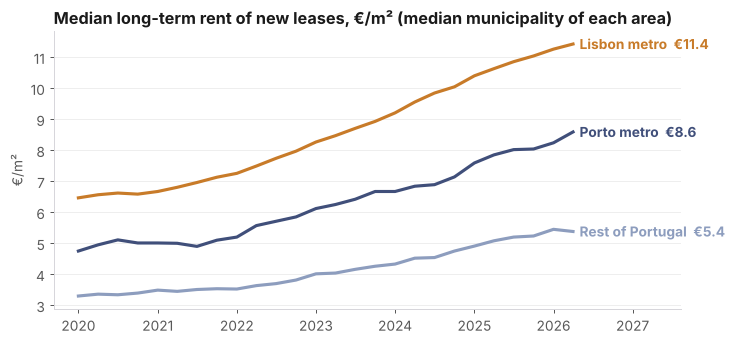

area,Lisbon metro,Porto metro,Rest of Portugal
quarter,,,
2020-01-01,6.46,4.75,3.30
2026-04-01,11.42,8.59,5.38


In [11]:
median_by_area = features_all_rows.groupby(["quarter", "area"])["rent_m2"].median().unstack()  # all quarters, up to 2026 Q2
median_by_area.index = median_by_area.index.to_timestamp()

fig, ax = plt.subplots(figsize=(9, 4))
for area, color in AREA_COLORS.items():
    series = median_by_area[area]
    ax.plot(series.index, series.values, color=color, linewidth=2.5)
    ax.text(series.index[-1], series.values[-1], f"  {area}  €{series.values[-1]:.1f}", color=color,
            va="center", fontweight="bold")
ax.set(title="Median long-term rent of new leases, €/m² (median municipality of each area)", ylabel="€/m²")
ax.yaxis.grid(True, color="#EEEEEE")
ax.set_xlim(right=median_by_area.index[-1] + pd.Timedelta(days=500))
save(fig, "02_rent_by_area_over_time.png")
median_by_area.iloc[[0, -1]].round(2)

### 3.2 How fast do rents grow in one year?

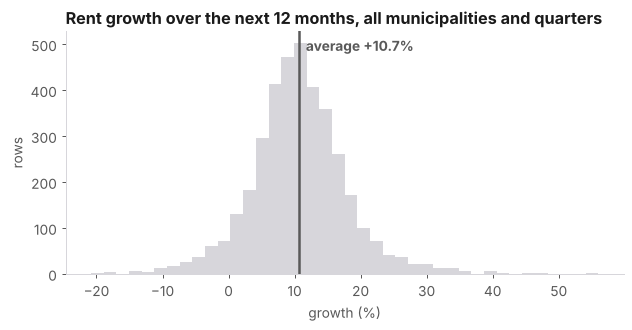

count    3788.000
mean        0.107
std         0.076
min        -0.208
25%         0.065
50%         0.104
75%         0.146
max         0.560
Name: target_growth_next_year, dtype: float64

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(model_dataset["target_growth_next_year"] * 100, bins=40, color=GREY)
mean_growth = model_dataset["target_growth_next_year"].mean() * 100
ax.axvline(mean_growth, color=DARK_GREY, linewidth=2)
ax.text(mean_growth, ax.get_ylim()[1] * 0.92, f"  average +{mean_growth:.1f}%", color=DARK_GREY, fontweight="bold")
ax.set(title="Rent growth over the next 12 months, all municipalities and quarters", xlabel="growth (%)", ylabel="rows")
save(fig, "03_target_growth_distribution.png")
model_dataset["target_growth_next_year"].describe().round(3)

### 3.3 The average growth changes over time

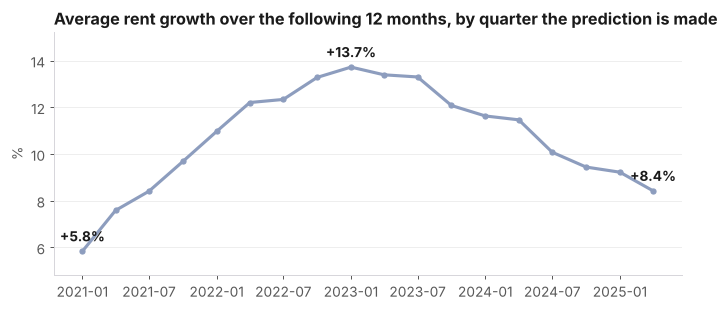

In [13]:
market_growth = model_dataset.groupby("quarter")["target_growth_next_year"].mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.5))
x = market_growth.index.to_timestamp()
ax.plot(x, market_growth.values, color=HIGHLIGHT, linewidth=2.5, marker="o", markersize=4)
for i in [0, int(np.argmax(market_growth.values)), len(market_growth) - 1]:
    ax.annotate(f"+{market_growth.values[i]:.1f}%", (x[i], market_growth.values[i]), textcoords="offset points",
                xytext=(0, 8), ha="center", color=TEXT, fontweight="bold")
ax.set(title="Average rent growth over the following 12 months, by quarter the prediction is made", ylabel="%",
       ylim=(market_growth.min() - 1, market_growth.max() + 1.5))
ax.yaxis.grid(True, color="#EEEEEE")
save(fig, "04_market_growth_by_quarter.png")

Growth accelerated until 2023 and has been slowing since. The model cannot know this in advance, so it is the
main source of error for any forecast.

### 3.4 Feature selection with correlation

First, which features move together with the target?

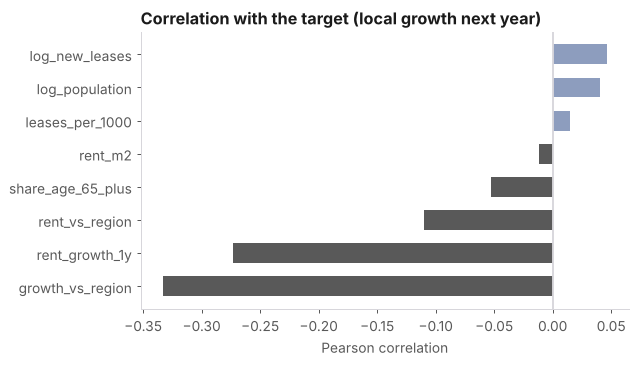

growth_vs_region    -0.33
rent_growth_1y      -0.27
rent_vs_region      -0.11
share_age_65_plus   -0.05
rent_m2             -0.01
leases_per_1000      0.01
log_population       0.04
log_new_leases       0.05
Name: target_local_growth, dtype: float64

In [14]:
CANDIDATE_FEATURES = NUMERIC_FEATURES + ["log_population"]
correlation = (model_dataset[CANDIDATE_FEATURES + [TARGET]].corr()[TARGET]
               .drop(TARGET).sort_values())
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(correlation.index, correlation.values,
        color=[DARK_GREY if value < 0 else HIGHLIGHT for value in correlation.values], height=0.6)
ax.axvline(0, color=GREY)
ax.set(title="Correlation with the target (local growth next year)", xlabel="Pearson correlation")
save(fig, "05_correlation_with_target.png")
correlation.round(2)

All correlations are **weak**, so this is a hard problem. The strongest ones are *negative*: municipalities whose rent grew
faster than their region last year tend to grow **slower** next year (a "cooling down" effect, called *mean reversion*):

slope: -0.36 -> 10 pp faster than the region today = 3.6 pp slower next year


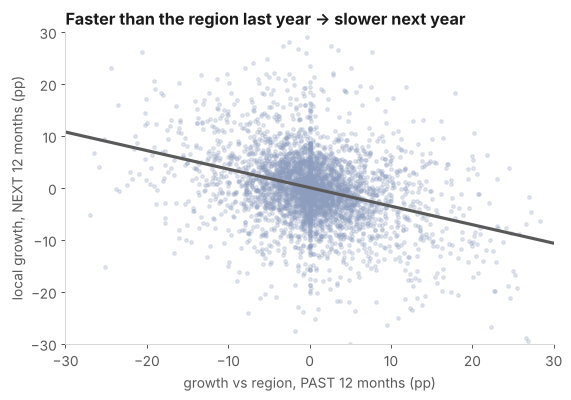

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(model_dataset["growth_vs_region"] * 100, model_dataset[TARGET] * 100, s=8, alpha=0.25, color=HIGHLIGHT)
slope, intercept = np.polyfit(model_dataset["growth_vs_region"], model_dataset[TARGET], 1)
x_line = np.linspace(-0.3, 0.3, 50)
ax.plot(x_line * 100, (slope * x_line + intercept) * 100, color=DARK_GREY, linewidth=2.5)
ax.set(title="Faster than the region last year -> slower next year", xlim=(-30, 30), ylim=(-30, 30),
       xlabel="growth vs region, PAST 12 months (pp)", ylabel="local growth, NEXT 12 months (pp)")
save(fig, "06_mean_reversion.png")
print(f"slope: {slope:.2f} -> 10 pp faster than the region today = {abs(slope) * 10:.1f} pp slower next year")

Second, do features repeat each other? If two features are almost the same (|correlation| > 0.9), I keep only one.

feature pairs with |correlation| > 0.9: [('log_new_leases', 'log_population')]


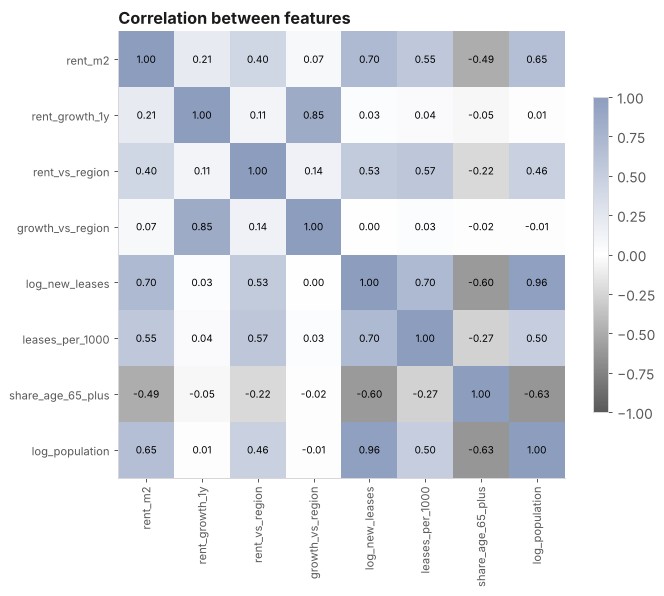

In [16]:
fig, ax = plt.subplots(figsize=(8, 6.5))
corr = model_dataset[CANDIDATE_FEATURES].corr()
from matplotlib.colors import LinearSegmentedColormap
grey_blue = LinearSegmentedColormap.from_list("grey_blue", [DARK_GREY, "white", HIGHLIGHT])
im = ax.imshow(corr, cmap=grey_blue, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=9)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation between features")
fig.colorbar(im, ax=ax, shrink=0.7)
save(fig, "07_feature_correlation_heatmap.png")

pairs = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("feature pairs with |correlation| > 0.9:", list(pairs[pairs > 0.9].index) or "none")

`log_new_leases` and `log_population` are almost the same information (0.96: bigger towns sign more contracts).
I keep `log_new_leases`, which is more correlated with the target, and **drop `log_population`**.
The final model uses **7 numbers + `area`** (the list `NUMERIC_FEATURES` in `src/modelling.py`):

In [17]:
print("final features:", NUMERIC_FEATURES + CATEGORICAL_FEATURES)

final features: ['rent_m2', 'rent_growth_1y', 'rent_vs_region', 'growth_vs_region', 'log_new_leases', 'leases_per_1000', 'share_age_65_plus', 'area']


## 4. Train/test split and a simple baseline

`train_test_split` would mix years at random. For a forecast that is not fair: the model would learn from rents
of the same year it is tested on. So I split **by time**:

| | Prediction made in | Rent predicted for |
|---|---|---|
| Train | 2021 Q1 - 2023 Q2 | 2022 Q1 - 2024 Q2 |
| Test | 2024 Q3 - 2025 Q2 | **2025 Q3 - 2026 Q2** (the most recent year INE has published) |

The training set only contains rows whose answer was known **before** 2024 Q3, so nothing from the test year leaks into training.

In [18]:
train, test = time_split(model_dataset, test_start=TEST_START_QUARTER)
y_test_rent = test["target_rent_next_year"]

average_growth = train["target_growth_next_year"].mean()
print(f"average growth in the training years: +{average_growth:.1%}")

train: 2,055 rows (2021Q1 -> 2023Q2) | test: 879 rows (2024Q3 -> 2025Q2)
average growth in the training years: +10.8%


Before any machine learning I need a score to beat. Two simple rules:

- **Rent stays the same:** next year's rent = rent today.
- **Average growth:** every rent grows by the training average (step 1 of my forecast, without the model).

In [19]:
baselines = pd.DataFrame([
    regression_scores(y_test_rent, test["rent_m2"], "Baseline: rent stays the same"),
    regression_scores(y_test_rent, test["rent_m2"] * (1 + average_growth), "Baseline: average growth"),
])
baselines.round(3)

,model,MAE,RMSE,R2
0,Baseline: rent stays the same,0.567,0.672,0.939
1,Baseline: average growth,0.305,0.416,0.977


"Rent stays the same" is wrong by **€0.57/m²** on average (MAE), because rents always rise.
"Average growth" is much better: **€0.305/m²**. This is the score the machine learning model has to beat.

R² is very high for both (above 0.9), because the *level* of the rent is easy to guess: Lisbon is expensive today
and next year. So my main metric is **MAE in €/m²** (easy to explain: "on average I am wrong by X euros per m²").

## 5. Preparing the features

Same steps as in class, all **fitted on the training data only** and then applied to the test data:

1. `SimpleImputer(strategy="mean")` - fill the few missing values with the mean.
2. `MinMaxScaler` - normalise every number to 0-1, so that KNN (based on distances) is not dominated by big numbers.
3. `OneHotEncoder` - turn `area` into 3 columns of 0/1.

In [20]:
preparer = FeaturePreparer().fit(train)
X_train = preparer.transform(train)
X_test = preparer.transform(test)
y_train = train[TARGET]
y_test = test[TARGET]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
pd.DataFrame(X_train, columns=preparer.feature_names()).describe().loc[["min", "mean", "max"]].round(2)

X_train: (2055, 10) | X_test: (879, 10)


,rent_m2,rent_growth_1y,rent_vs_region,growth_vs_region,log_new_leases,leases_per_1000,share_age_65_plus,area_Lisbon metro,area_Porto metro,area_Rest of Portugal
min,0.0,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
mean,0.2,0.46,0.33,0.43,0.32,0.28,0.4,0.09,0.08,0.83
max,1.0,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00,1.00


## 6. Comparing regression models

I try the 7 regression models seen in class with simple settings. To compare them **without touching the test set**,
I use **5-fold cross-validation** on the training data (`cross_val_score`, `cv=5`, as in class).
The score is the MAE of y (local growth), in **percentage points**.

Note: my rows are sorted by municipality, so with `cv=5` each fold holds **different municipalities**: the model is
always validated on towns it did not see. I first tried shuffling the rows, but then the same town (in neighbouring
quarters) ends up in both training and validation, the score looks too good and tuning picks models that overfit.

In [21]:
cv = 5
models = candidate_models()

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    cv_rows.append({"model": name, "cv_MAE_pp": -scores.mean() * 100})
cv_results = pd.DataFrame(cv_rows).sort_values("cv_MAE_pp").reset_index(drop=True)
cv_results.round(2)

,model,cv_MAE_pp
0,Random forest,4.65
1,Bagging,4.66
2,AdaBoost,4.77
3,Gradient boosting,4.79
4,Linear regression,4.81
5,KNN,4.88
6,Decision tree,5.06


The models are close to each other (between 4.65 and 5.06 pp). The best ones with simple
settings are **random forest** and **bagging** - ensembles of many trees are more stable than one single
decision tree.

## 7. Hyperparameter tuning

I tune three models:

| Model | Method | Parameters |
|---|---|---|
| Random forest | `GridSearchCV` (tries every combination) | `n_estimators`, `max_depth`, `min_samples_leaf` |
| Gradient boosting | `RandomizedSearchCV` (tries 20 random combinations) | `n_estimators`, `max_depth`, `learning_rate` |
| KNN | `GridSearchCV` | `n_neighbors` |

In [22]:
rf_grid = {"n_estimators": [100, 300], "max_depth": [3, 5, 8], "min_samples_leaf": [5, 20, 50]}
rf_search = GridSearchCV(RandomForestRegressor(random_state=0, n_jobs=-1), rf_grid, cv=cv,
                         scoring="neg_mean_absolute_error")
rf_search.fit(X_train, y_train)
print("Random forest best parameters:", rf_search.best_params_)

Random forest best parameters: {'max_depth': 5, 'min_samples_leaf': 20, 'n_estimators': 300}


In [23]:
gb_grid = {"n_estimators": [50, 100, 200, 400], "max_depth": [2, 3, 4], "learning_rate": [0.01, 0.05, 0.1]}
gb_search = RandomizedSearchCV(GradientBoostingRegressor(random_state=0), gb_grid, n_iter=20, cv=cv,
                               scoring="neg_mean_absolute_error", random_state=0)
gb_search.fit(X_train, y_train)
print("Gradient boosting best parameters:", gb_search.best_params_)

Gradient boosting best parameters: {'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.01}


In [24]:
knn_grid = {"n_neighbors": [5, 10, 20, 30, 50, 75, 100]}
knn_search = GridSearchCV(KNeighborsRegressor(), knn_grid, cv=cv, scoring="neg_mean_absolute_error")
knn_search.fit(X_train, y_train)
print("KNN best parameters:", knn_search.best_params_)

KNN best parameters: {'n_neighbors': 30}


**Did tuning help?** Cross-validation error before (simple settings) and after tuning:

In [25]:
searches = {"Random forest": rf_search, "Gradient boosting": gb_search, "KNN": knn_search}
cv_before = cv_results.set_index("model")["cv_MAE_pp"]
tuning = pd.DataFrame([{"model": name,
                        "cv_MAE_before_pp": cv_before[name],
                        "cv_MAE_after_pp": -search.best_score_ * 100,
                        "best_parameters": search.best_params_} for name, search in searches.items()])
tuning.round(3)

,model,cv_MAE_before_pp,cv_MAE_after_pp,best_parameters
0,Random forest,4.654,4.636,"{'max_depth': 5, 'min_samples_leaf': 20, 'n_es..."
1,Gradient boosting,4.785,4.621,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."
2,KNN,4.881,4.702,{'n_neighbors': 30}


Tuning lowers the cross-validation error of all three models. The best settings are **simple** models
(shallow trees, many neighbours, a slow learning rate): the signal is weak, so the models must avoid **overfitting**
(learning noise from the training years).

### 7.1 Choosing the final model

I pick the model with the **best cross-validation score** (not the best test score, which would be cheating):

In [26]:
for name, search in searches.items():
    models[name + " (tuned)"] = search.best_estimator_
    cv_rows.append({"model": name + " (tuned)", "cv_MAE_pp": -search.best_score_ * 100})
cv_all = pd.DataFrame(cv_rows).sort_values("cv_MAE_pp").reset_index(drop=True)

final_model_name = cv_all.loc[0, "model"]
final_model = models[final_model_name]
print("final model:", final_model_name, f"| cv MAE {cv_all.loc[0, 'cv_MAE_pp']:.2f} pp")

final model: Gradient boosting (tuned) | cv MAE 4.62 pp


## 8. Results on the test year (rents of 2025 Q3 - 2026 Q2)

Now I train every model on all the training data and check it **once** on the test year.
The model's prediction is turned back into a rent in €/m²:
`predicted rent = rent today x (1 + average growth + model prediction)`.

In [27]:
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    growth, rent_pred = predict_rent(model, X_test, test, average_growth)
    rows.append({**regression_scores(y_test_rent, rent_pred, name),
                 "top_20pct_hit_rate": top_20_hit_rate(test, growth)})
results = pd.concat([baselines, pd.DataFrame(rows)], ignore_index=True).sort_values("MAE").reset_index(drop=True)
results.round(3)

,model,MAE,RMSE,R2,top_20pct_hit_rate
0,Baseline: average growth,0.305,0.416,0.977,NaN
1,KNN (tuned),0.311,0.435,0.974,0.351
2,KNN,0.320,0.442,0.974,0.293
3,Random forest (tuned),0.321,0.435,0.974,0.420
4,Gradient boosting,0.322,0.435,0.974,0.374
5,Gradient boosting (tuned),0.322,0.436,0.974,0.376
6,Random forest,0.327,0.442,0.974,0.402
7,Bagging,0.327,0.442,0.974,0.402
8,AdaBoost,0.352,0.475,0.969,0.369
9,Decision tree,0.365,0.508,0.965,0.339


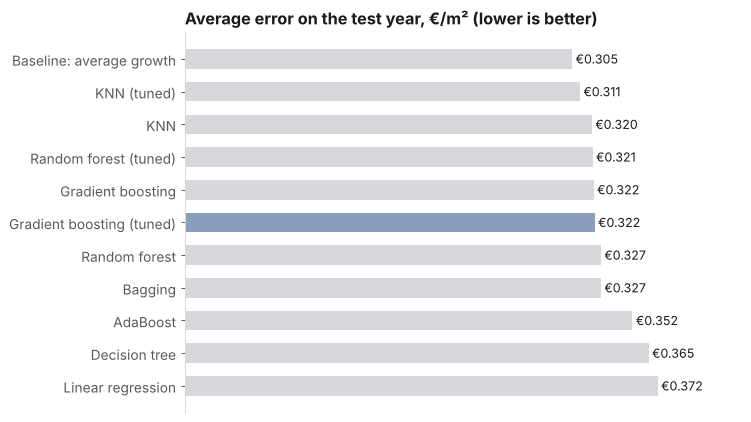

In [28]:
chart = results[~results["model"].str.contains("stays the same")]  # off the scale, shown in the text
fig, ax = plt.subplots(figsize=(8, 5.5))
horizontal_bars(ax, chart["model"].tolist(), chart["MAE"].tolist(),
                value_format="€{:.3f}", highlight=final_model_name)
ax.invert_yaxis()  # lowest error on top
ax.set_title("Average error on the test year, €/m² (lower is better)")
save(fig, "08_model_comparison.png")

**What the test year shows**

- The final model, **tuned gradient boosting**, is wrong by **€0.322/m²** on average (RMSE €0.44, R² 0.97).
  On a typical rent of €5.84/m² that is about 6%.
- The simple **average growth** baseline is about as accurate (€0.305/m²): the model does **not** beat it on the
  € error. Most of the accuracy comes from step 1 (the average growth); the correction per municipality changes the
  € error very little.
- Linear regression is the worst model (€0.372/m²).
- Where the model helps is **ranking**: of the municipalities it puts in the top 20% for growth, **38%** really were in the
  top 20% (1.9x a random guess of 20%). The baseline cannot rank at all - it gives every municipality the same growth.

### 8.1 Predicted vs real rent

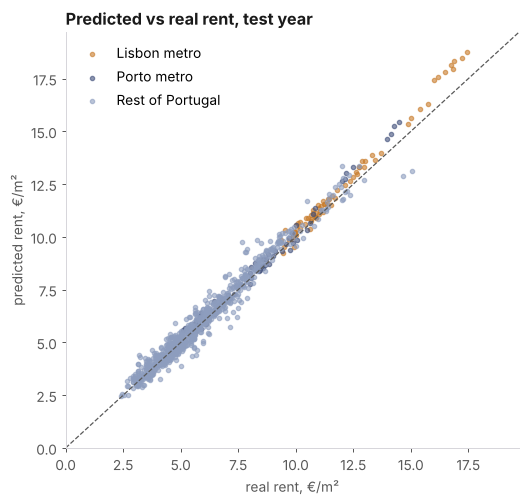

,mean_absolute_error,mean_error,rows
area,,,
Lisbon metro,0.444,0.420,72
Porto metro,0.295,0.231,68
Rest of Portugal,0.313,0.135,739


In [29]:
final_growth, final_rent_pred = predict_rent(final_model, X_test, test, average_growth)
test_results = test[["municipality", "region_name", "area", "quarter", "rent_m2", "target_rent_next_year",
                     "target_growth_next_year"]].copy()
test_results["predicted_rent_next_year"] = final_rent_pred
test_results["predicted_growth_next_year"] = final_growth
test_results["error_eur_m2"] = test_results["predicted_rent_next_year"] - test_results["target_rent_next_year"]

fig, ax = plt.subplots(figsize=(6.5, 6))
for area, color in AREA_COLORS.items():
    rows = test_results[test_results["area"] == area]
    ax.scatter(rows["target_rent_next_year"], rows["predicted_rent_next_year"], s=12, alpha=0.6, color=color, label=area)
ax.legend()
limit = test_results[["target_rent_next_year", "predicted_rent_next_year"]].max().max() * 1.05
ax.plot([0, limit], [0, limit], color=DARK_GREY, linestyle="--", linewidth=1)
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="real rent, €/m²", ylabel="predicted rent, €/m²",
       title="Predicted vs real rent, test year")
save(fig, "09_predicted_vs_real.png")

errors_by_area = test_results.groupby("area")["error_eur_m2"].agg(
    mean_absolute_error=lambda e: e.abs().mean(), mean_error="mean", rows="size").round(3)
errors_by_area

Points close to the dashed line are good predictions. The error is largest in the Lisbon metro area, where rents
(and therefore € errors) are highest. A positive mean error means the model over-estimated: the test year grew
less than the average of the training years (section 3.3).

### 8.2 Confusion matrix: does the model find the fastest-growing municipalities?

A confusion matrix is for **classification**, and my model is a regression. But I can turn its output into a
yes/no question that matters to an investor: *"Will this municipality be in the top 20% for rent growth next year?"*

- **Real class:** the municipality really was in the top 20% of growth in that quarter.
- **Predicted class:** the model put it in its own top 20%.

A random guess would be right about 20% of the time when it says "top 20%". (This is the same check as the
"top-20% hit rate" in section 8, now shown as a matrix.)

              precision    recall  f1-score   support

 not top 20%       0.85      0.85      0.85       705
     top 20%       0.38      0.37      0.37       174

    accuracy                           0.75       879
   macro avg       0.61      0.61      0.61       879
weighted avg       0.75      0.75      0.75       879



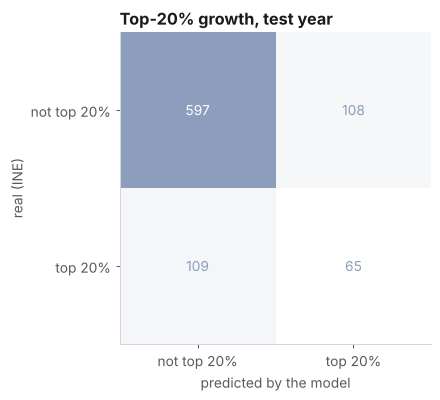

In [30]:
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix

top20 = test_results[["quarter", "target_growth_next_year", "predicted_growth_next_year"]].copy()
by_quarter = top20.groupby("quarter")
top20["real_top_20"] = by_quarter["target_growth_next_year"].rank(ascending=False, pct=True) <= 0.2
top20["predicted_top_20"] = by_quarter["predicted_growth_next_year"].rank(ascending=False, pct=True) <= 0.2

matrix = confusion_matrix(top20["real_top_20"], top20["predicted_top_20"])
display = ConfusionMatrixDisplay(matrix, display_labels=["not top 20%", "top 20%"])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
display.plot(ax=ax, cmap=LinearSegmentedColormap.from_list("white_blue", ["white", HIGHLIGHT]), colorbar=False)
ax.set(xlabel="predicted by the model", ylabel="real (INE)", title="Top-20% growth, test year")
save(fig, "12_confusion_matrix.png")

print(classification_report(top20["real_top_20"], top20["predicted_top_20"],
                            target_names=["not top 20%", "top 20%"]))

**How to read it** (879 predictions = municipalities x 4 test quarters)

- **True positives (65):** the model said "top 20%" and it was right.
- **False positives (108):** the model said "top 20%" but the municipality grew less.
- **False negatives (109):** fast-growing municipalities the model missed.
- **True negatives (597):** correctly "not top 20%".

**Precision** for "top 20%" is **38%**: when the model says a municipality will be in the top 20%, it is right
38% of the time, against ~20% for a random guess. **Recall** is 37%: it finds 37% of the real top 20%.
The accuracy (75%) looks high only because most municipalities are "not top 20%" (an imbalanced problem),
so precision and recall are the numbers to look at.

## 9. Feature importance

Which features matter most? Tree models have `feature_importances_`. I use the final model (or the tuned random forest if the final model were KNN, which has no importances):

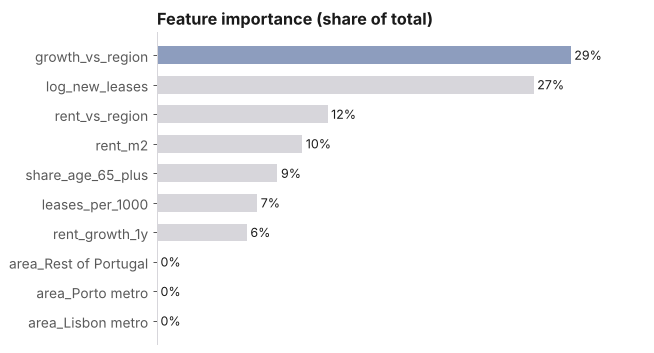

growth_vs_region         0.292
log_new_leases           0.266
rent_vs_region           0.120
rent_m2                  0.103
share_age_65_plus        0.085
leases_per_1000          0.071
rent_growth_1y           0.063
area_Lisbon metro        0.000
area_Porto metro         0.000
area_Rest of Portugal    0.000
dtype: float64

In [31]:
tree_model = final_model if hasattr(final_model, "feature_importances_") else models["Random forest (tuned)"]
importance = pd.Series(tree_model.feature_importances_, index=preparer.feature_names()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
horizontal_bars(ax, list(importance.index), (importance * 100).tolist(), value_format="{:.0f}%",
                highlight=importance.index[0])
ax.set_title("Feature importance (share of total)")
save(fig, "10_feature_importance.png")
importance.round(3)

- **`growth_vs_region`** is the most important feature: municipalities that grew faster than their region tend to slow down,
  and those that lagged behind tend to catch up.
- Next come `log_new_leases` and `rent_vs_region`.
- `area` has almost no importance: comparing each municipality with its neighbours already captures location.

## 10. 2027 outlook - forecast, actual outcomes not yet available

Sections 4-9 are the **evidence of performance**: they compare predictions with rents INE has already published
(July 2025 - June 2026). This section is only an **application** of the same model.

I train the final model again on **all** rows with a known target and apply it to the latest data, **2026 Q2**.
The result is an **estimate** of the rent of **2027 Q2** (contracts signed July 2026 - June 2027).
The real values do not exist yet, so these figures cannot be checked and are not used for any accuracy claim.

In [32]:
preparer_all = FeaturePreparer().fit(model_dataset)
final_model.fit(preparer_all.transform(model_dataset), model_dataset[TARGET])
average_growth_all = model_dataset["target_growth_next_year"].mean()

latest_rows = drop_unusable_rows(features_all_rows[features_all_rows["quarter"] == features_all_rows["quarter"].max()],
                                 need_target=False)
forecast_growth, forecast_rent = predict_rent(final_model, preparer_all.transform(latest_rows), latest_rows,
                                              average_growth_all)

forecast = latest_rows[["municipality_code", "municipality", "region_code", "area", "rent_m2", "population"]].copy()
forecast["region_name"] = forecast["region_code"].map(region_name)
forecast["forecast_rent_2027q2"] = forecast_rent.round(2)
forecast["forecast_growth_pct"] = (forecast_growth * 100).round(1)
forecast["vs_portugal_pp"] = ((forecast_growth - average_growth_all) * 100).round(1)
forecast = forecast.rename(columns={"rent_m2": "rent_2026q2"}).sort_values("forecast_growth_pct", ascending=False)
forecast["rank"] = range(1, len(forecast) + 1)
print(f"average growth used: +{average_growth_all:.1%} | municipalities forecast: {len(forecast)}")
forecast.head(10)

kept 228 of 278 rows (228 municipalities)
average growth used: +10.7% | municipalities forecast: 228


,municipality_code,municipality,region_code,area,rent_2026q2,population,region_name,forecast_rent_2027q2,forecast_growth_pct,vs_portugal_pp,rank
52,0505,Idanha-a-Nova,195,Rest of Portugal,3.21,8360,Beira Baixa,3.91,21.9,11.1,1
46,0409,Torre de Moncorvo,11D,Rest of Portugal,3.13,6507,Douro,3.81,21.7,10.9,2
101,0910,Pinhel,196,Rest of Portugal,2.94,8040,Beiras e Serra da Estrela,3.51,19.4,8.6,3
157,1314,Santo Tirso,11A,Porto metro,5.88,69810,Área Metropolitana do Porto,6.93,17.8,7.1,4
72,0703,Borba,1C4,Rest of Portugal,3.03,6542,Alentejo Central,3.56,17.4,6.6,5
3,0104,Arouca,11A,Porto metro,5.28,21459,Área Metropolitana do Porto,6.19,17.2,6.5,6
12,0113,Oliveira de Azeméis,11A,Porto metro,5.81,70027,Área Metropolitana do Porto,6.77,16.6,5.8,7
56,0601,Arganil,192,Rest of Portugal,4.53,11437,Região de Coimbra,5.27,16.3,5.5,8
27,0213,Serpa,1C2,Rest of Portugal,4.35,14428,Baixo Alentejo,5.04,15.8,5.1,9
132,1112,Sobral de Monte Agraço,1D1,Rest of Portugal,7.10,11858,Oeste,8.22,15.7,5.0,10


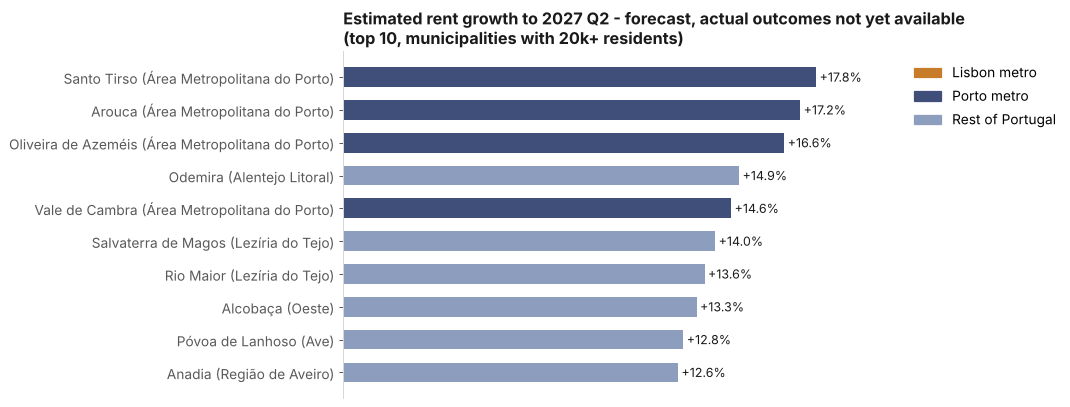

In [33]:
top = forecast[forecast["population"] >= 20_000].head(10)  # skip very small municipalities for readability
fig, ax = plt.subplots(figsize=(8, 5))
horizontal_bars(ax, [f"{m} ({r})" for m, r in zip(top["municipality"], top["region_name"])],
                top["forecast_growth_pct"].tolist(), value_format="+{:.1f}%",
                colors=top["area"].map(AREA_COLORS).tolist())
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in AREA_COLORS.values()], labels=list(AREA_COLORS),
          loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Estimated rent growth to 2027 Q2 - forecast, actual outcomes not yet available\n(top 10, municipalities with 20k+ residents)")
save(fig, "11_forecast_top10_2027.png")

In [34]:
by_area = forecast.groupby("area").agg(median_rent_2026q2=("rent_2026q2", "median"),
                                       median_forecast_2027q2=("forecast_rent_2027q2", "median"),
                                       median_growth_pct=("forecast_growth_pct", "median"),
                                       municipalities=("municipality", "size")).round(2)
by_area

,median_rent_2026q2,median_forecast_2027q2,median_growth_pct,municipalities
area,,,,
Lisbon metro,11.42,12.64,10.5,18
Porto metro,8.59,9.52,10.7,17
Rest of Portugal,5.54,6.15,10.7,193


**Reading the forecast (estimates, not results)**

- The estimates assume rents keep growing at the average pace of the past years (+10.7%). Section 3.3 showed that
  growth has been slowing; if it keeps slowing, every estimate moves down by the same few points.
- In the test year the model's top-20% picks were right 38% of the time, so the **ranking** is the most useful part,
  but it is a likelihood, not a certainty.

## 11. Export for Tableau

Three tidy tables for the dashboard. All three cover the same municipalities (the ones with a 2027 forecast),
so they match one-to-one in Tableau:

In [35]:
TABLEAU_DIR.mkdir(exist_ok=True)

# Only the municipalities that have a 2027 forecast, so every row matches in Tableau (no "Null" members)
forecast_codes = set(forecast["municipality_code"])
history = panel.merge(features_all_rows[["municipality_code", "quarter", "area"]], on=["municipality_code", "quarter"])
history = history[history["municipality_code"].isin(forecast_codes)]
history["region_name"] = history["region_code"].map(region_name)
history["quarter_start_date"] = history["quarter"].dt.start_time.dt.date
history["quarter"] = history["quarter"].astype(str)
history.to_csv(TABLEAU_DIR / "rent_history.csv", index=False)

test_export = test_results.assign(municipality_code=test["municipality_code"].values)
test_export = test_export[test_export["municipality_code"].isin(forecast_codes)]
test_export["quarter_predicted"] = (test_export["quarter"] + 4).astype(str)
test_export["quarter"] = test_export["quarter"].astype(str)
test_export = test_export[[c for c in test_export.columns if c != "municipality_code"] + ["municipality_code"]]
test_export.round(4).to_csv(TABLEAU_DIR / "test_predictions.csv", index=False)

forecast.to_csv(TABLEAU_DIR / "forecast_2027.csv", index=False)
for file in sorted(TABLEAU_DIR.glob("*.csv")):
    print(file.name, pd.read_csv(file).shape)

forecast_2027.csv (228, 11)
rent_history.csv (5928, 9)
test_predictions.csv (874, 12)


## 12. Conclusions

**Objective:** predict the long-term rent (€/m²) of new leases in each municipality of Portugal one year ahead (regression).

**What I found** (all accuracy figures come from the test year: rents of July 2025 - June 2026, compared with the real INE values)

1. My final model (tuned gradient boosting) predicts next year's rent with an average error of **€0.32/m²** (about 6%).
2. A simple rule - "every rent grows by the average" - is about as accurate (€0.30/m²). Most of the accuracy comes from
   the average growth; machine learning does not reduce the € error.
3. Machine learning adds value in **ranking**: it finds the fastest-growing 20% of municipalities **1.9x better than chance**.
4. Rents show **mean reversion**: municipalities that grew faster than their region tend to slow down, and cheaper ones catch up.
5. **2027 outlook (forecast, actual outcomes not yet available):** the model gives estimates for 228 municipalities.
   They will only be verifiable when INE publishes the 2027 data.

**Limitations**

- Only ~5 years of data, during an unusual boom: the average growth may not hold if the market slows down.
- Only municipalities with an active rental market (~33+ new contracts a year) have a published rent.
- Nominal prices, declared leases only (INE); no data on income, interest rates or new housing supply.

**Next steps**

- Add macro data (interest rates, wages, inflation) to predict the average growth itself.
- Add parish-level data to predict *within* Lisbon and Porto.
- Re-run every quarter when INE publishes new data and check how well the 2027 forecast does.